# Laboratorio 4: Problema Inverso en el Modelo SIR: Calibración y Sesgo de Discretización

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nabw/UNA-taller/blob/main/notebooks/solucion/04_calibracion_problema_inverso.ipynb)


## 1. Introducción: El Problema Inverso en Ciencia de Datos

En los laboratorios anteriores abordamos el **problema directo**: dados los parámetros físicos $(\beta, \gamma)$ y las condiciones iniciales, integramos numéricamente el sistema diferencial para calcular la trayectoria temporal $I(t)$.

En la práctica de la ciencia de datos y la epidemiología cuantitativa, la situación es la opuesta: se tiene acceso a una serie temporal de observaciones clínicas con ruido $I^{\text{obs}}_k$ en los instantes $t_k$, y se desea resolver el **problema inverso**: estimar el vector de parámetros generativos $\theta = (\beta, \gamma)$ que mejor describe los datos observados.

### El Fenómeno del Sesgo de Discretización (Discretization Bias)

Todo algoritmo de calibración optimiza los parámetros evaluando repetidamente un simulador numérico hacia adelante. Si este simulador utiliza un esquema con un paso temporal finito $\Delta t$, el integrador comete un error de truncamiento local. Durante el proceso de ajuste, el optimizador compensa de forma artificial los defectos del integrador numérico, desplazando los estimadores $\hat{\beta}(\Delta t)$ y $\hat{\gamma}(\Delta t)$ lejos de sus valores verdaderos continuos $\beta^*$ y $\gamma^*$. Este sesgo sistemático no proviene del ruido de los datos, sino estrictamente de la aproximación numérica de las derivadas continuas.

## Objetivos de Aprendizaje

1. Formular computacionalmente la función de pérdida por mínimos cuadrados $L(\beta, \gamma)$.
2. Explorar y mapear la superficie de pérdida bidimensional mediante un gráfico de contornos.
3. Implementar la calibración de parámetros utilizando el algoritmo Nelder-Mead y registrar la trayectoria del símplex.
4. Ejecutar un experimento controlado evaluando $\Delta t \in [0.05, 0.10, 0.25, 0.50, 0.80, 1.00, 1.50]$ para cuantificar rigurosamente el sesgo de discretización sobre $\hat{\beta}$ y $\hat{R}_0$.
5. Analizar el impacto de este sesgo numérico en la toma de decisiones de salud pública (umbral de vacunación).


In [1]:
# Celda de configuración y librerías científicas autocontenidas
import os
os.environ.setdefault("MPLCONFIGDIR", "/tmp/matplotlib")
from typing import Any
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.integrate import solve_ivp

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams.update({
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 12,
    "figure.titlesize": 13,
    "lines.linewidth": 2.0,
    "grid.alpha": 0.4
})

# --------------------------------------------------------------------------
# Funciones auxiliares autocontenidas para integración y datos sintéticos
# --------------------------------------------------------------------------
def sir_imex_integrador(
    beta: float,
    gamma: float,
    dt: float,
    T: float,
    S0: float = 0.99,
    I0: float = 0.01
) -> tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    """Integrador IMEX conservativo para el modelo SIR."""
    n_steps = int(np.round(T / dt))
    t = np.linspace(0.0, n_steps * dt, n_steps + 1)
    S = np.zeros(n_steps + 1, dtype=np.float64)
    I = np.zeros(n_steps + 1, dtype=np.float64)
    R = np.zeros(n_steps + 1, dtype=np.float64)
    S[0], I[0], R[0] = S0, I0, 1.0 - S0 - I0

    for n in range(n_steps):
        contagio = dt * beta * S[n] * I[n]
        S[n + 1] = S[n] - contagio
        I[n + 1] = (I[n] + contagio) / (1.0 + dt * gamma)
        R[n + 1] = R[n] + dt * gamma * I[n + 1]

    return t, S, I, R

def generar_observaciones_referencia(
    beta_true: float = 0.4,
    gamma_true: float = 0.1,
    S0: float = 0.99,
    I0: float = 0.01,
    T: float = 50.0,
    sigma: float = 0.02,
    seed: int = 42
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Genera observaciones sintéticas con ruido Gaussiano."""
    def sir_ode(t, y):
        s, i, _ = y
        return [-beta_true * s * i, beta_true * s * i - gamma_true * i, gamma_true * i]

    sol = solve_ivp(
        sir_ode, (0.0, T), [S0, I0, 1.0 - S0 - I0],
        t_eval=np.linspace(0.0, T, 5001), method="RK45", rtol=1e-10, atol=1e-12
    )
    t_obs = np.arange(0.0, T + 1.0, 1.0)
    I_clean = np.interp(t_obs, sol.t, sol.y[1])
    rng = np.random.default_rng(seed)
    noise = rng.normal(0.0, sigma, size=I_clean.shape)
    I_noisy = np.maximum(0.0, I_clean + noise)
    return t_obs, I_clean, I_noisy

t_obs, I_clean, I_obs = generar_observaciones_referencia()
print(f"Datos sintéticos generados: {len(t_obs)} observaciones diarias.")


Datos sintéticos generados: 51 observaciones diarias.


## 2. Formulación de la Función de Pérdida por Mínimos Cuadrados

Buscamos el vector de parámetros $\theta = (\beta, \gamma)$ que minimice la discrepancia cuadrática entre la solución numérica simulada $I^{\text{sim}}(t_k; \theta)$ y las observaciones clínicas $I^{\text{obs}}_k$:

$$L(\beta, \gamma) = \sum_{k=0}^M \left( I^{\text{sim}}(t_k; \beta, \gamma) - I^{\text{obs}}_k \right)^2$$

### Restricción de Positividad Física

En epidemiología matemática, las tasas de transmisión y recuperación deben ser estrictamente positivas ($\beta > 0$ y $\gamma > 0$). Para preservar esta condición en optimizadores sin restricciones de caja, asignamos una penalización severa ($10^6$) a cualquier configuración paramétrica con valores no positivos o que induzca divergencias numéricas.


In [2]:
def funcion_perdida(
    theta: tuple[float, float] | list[float] | np.ndarray,
    t_obs: np.ndarray,
    I_obs: np.ndarray,
    dt_sim: float = 0.10,
    S0: float = 0.99,
    I0: float = 0.01
) -> float:
    """
    Calcula la suma de errores cuadráticos entre la simulación SIR y las observaciones.
    """
    beta, gamma = float(theta[0]), float(theta[1])
    PENALIZACION = 1e6

    if beta <= 0.0 or gamma <= 0.0:
        return PENALIZACION

    T_final = float(t_obs[-1])
    t_sim, _, I_sim, _ = sir_imex_integrador(beta, gamma, dt_sim, T_final, S0, I0)

    if np.any(np.isnan(I_sim)) or np.any(np.isinf(I_sim)) or np.any(I_sim < -1e-3) or np.any(I_sim > 2.0):
        return PENALIZACION

    # Interpolar sobre los tiempos de observación
    I_interp = np.interp(t_obs, t_sim, I_sim)
    residuos = I_interp - I_obs
    loss = float(np.sum(residuos ** 2))

    if np.isnan(loss) or np.isinf(loss):
        return PENALIZACION

    return loss


In [3]:
# Pruebas de validación para funcion_perdida
loss_true = funcion_perdida([0.4, 0.1], t_obs, I_obs, dt_sim=0.10)
assert isinstance(loss_true, float), "La pérdida debe retornar un número float."
assert loss_true < 0.1, f"La pérdida en los parámetros verdaderos debe ser pequeña, obtenida: {loss_true}"
# Verificar penalización ante parámetros inválidos
assert funcion_perdida([-0.1, 0.1], t_obs, I_obs) == 1e6, "Parámetro beta negativo debe ser penalizado."
assert funcion_perdida([0.4, -0.05], t_obs, I_obs) == 1e6, "Parámetro gamma negativo debe ser penalizado."
print(f"Validación de funcion_perdida: EXITOSA (pérdida en theta*: {loss_true:.5f}).")


Validación de funcion_perdida: EXITOSA (pérdida en theta*: 0.01204).


## 3. Mapeo del Paisaje de Pérdida (Rejilla Bidimensional)

Para analizar la convexidad local y la correlación entre parámetros, evaluamos la función de costo sobre una rejilla regular de prueba en el plano $(\beta, \gamma)$:
- $\beta \in [0.20, 0.60]$
- $\gamma \in [0.03, 0.20]$


In [4]:
def evaluar_malla_perdida(
    beta_vals: np.ndarray,
    gamma_vals: np.ndarray,
    t_obs: np.ndarray,
    I_obs: np.ndarray,
    dt_sim: float = 0.10,
    S0: float = 0.99,
    I0: float = 0.01
) -> np.ndarray:
    """
    Evalúa la pérdida sobre una rejilla bidimensional regular de parámetros.
    """
    n_gamma = len(gamma_vals)
    n_beta = len(beta_vals)
    L_grid = np.zeros((n_gamma, n_beta), dtype=np.float64)

    for i in range(n_gamma):
        g = float(gamma_vals[i])
        for j in range(n_beta):
            b = float(beta_vals[j])
            L_grid[i, j] = funcion_perdida([b, g], t_obs, I_obs, dt_sim, S0, I0)

    return L_grid


In [5]:
# Pruebas de validación para evaluar_malla_perdida
b_test = np.linspace(0.3, 0.5, 3)
g_test = np.linspace(0.08, 0.12, 3)
grid_test = evaluar_malla_perdida(b_test, g_test, t_obs, I_obs, dt_sim=0.20)
assert grid_test.shape == (3, 3), f"Forma esperada (3, 3), obtenida {grid_test.shape}"
assert np.all(grid_test >= 0.0), "Todos los valores de pérdida deben ser positivos."
print("Validación de evaluar_malla_perdida: EXITOSA.")


Validación de evaluar_malla_perdida: EXITOSA.


## 4. Calibración con el Algoritmo Símplex de Nelder-Mead

El algoritmo de Nelder-Mead (1965) es un método de optimización heurístico libre de derivadas. En cada iteración, actualiza dinámicamente un polígono de $d+1$ vértices en $\mathbb{R}^d$ (un triángulo para $d=2$) mediante operaciones de reflexión, expansión y contracción. Implementamos un callback para registrar el historial de posiciones del símplex a lo largo de las iteraciones.


In [6]:
def calibrar_sir(
    theta_init: tuple[float, float] | list[float] | np.ndarray,
    t_obs: np.ndarray,
    I_obs: np.ndarray,
    dt_sim: float = 0.10,
    S0: float = 0.99,
    I0: float = 0.01,
    track_history: bool = True
) -> dict[str, Any]:
    """
    Calibra beta y gamma minimizando la función de pérdida con Nelder-Mead.
    """
    history = [np.array(theta_init, dtype=np.float64).copy()]

    def callback(xk):
        history.append(np.array(xk, dtype=np.float64).copy())

    def objective(theta):
        return funcion_perdida(theta, t_obs, I_obs, dt_sim, S0, I0)

    res = minimize(
        objective,
        x0=np.array(theta_init, dtype=np.float64),
        method="Nelder-Mead",
        callback=callback if track_history else None,
        options={"maxiter": 500, "xatol": 1e-6, "fatol": 1e-6, "disp": False}
    )

    b_hat, g_hat = float(res.x[0]), float(res.x[1])
    r0_hat = b_hat / g_hat if g_hat > 0.0 else np.nan

    return {
        "theta_hat": res.x,
        "beta_hat": b_hat,
        "gamma_hat": g_hat,
        "R0_hat": r0_hat,
        "loss_val": float(res.fun),
        "success": bool(res.success),
        "iterations": int(res.nit),
        "history": np.array(history, dtype=np.float64)
    }


In [7]:
# Pruebas de validación para calibrar_sir
calib_test = calibrar_sir([0.2, 0.2], t_obs, I_obs, dt_sim=0.10)
assert calib_test["success"], "La optimización de Nelder-Mead debió converger exitosamente."
assert np.isclose(calib_test["beta_hat"], 0.4, atol=0.03), f"beta estimada lejana: {calib_test['beta_hat']}"
assert np.isclose(calib_test["gamma_hat"], 0.1, atol=0.02), f"gamma estimada lejana: {calib_test['gamma_hat']}"
print(f"Validación de calibrar_sir: EXITOSA (beta_hat: {calib_test['beta_hat']:.4f}, gamma_hat: {calib_test['gamma_hat']:.4f}).")


Validación de calibrar_sir: EXITOSA (beta_hat: 0.4046, gamma_hat: 0.0991).


## 5. Visualización de la Superficie de Costo y Descenso del Símplex

Graficamos el mapa de curvas de nivel de $L(\beta, \gamma)$ evaluado en $\Delta t = 0.10$, superponiendo la trayectoria seguida por el símplex de Nelder-Mead desde el punto inicial $\theta_0 = (0.20, 0.20)$ hasta el óptimo estimado, comparado con el valor verdadero continuo.


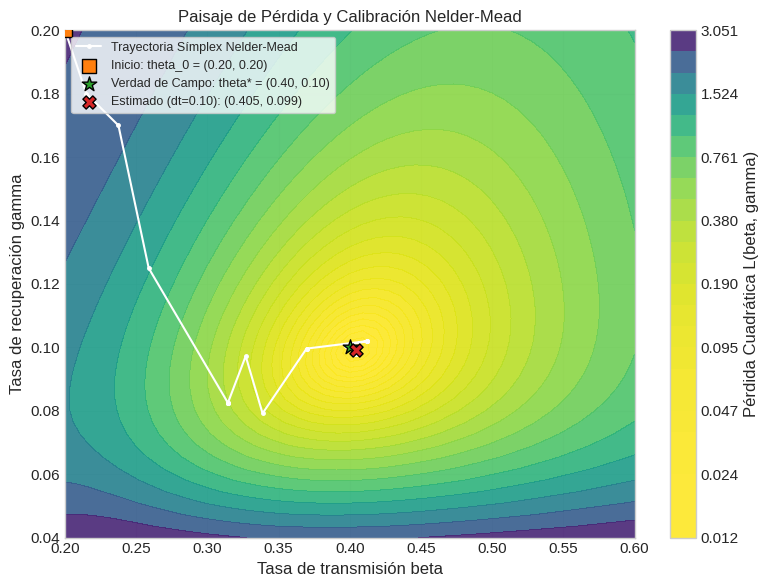

In [8]:
b_grid = np.linspace(0.20, 0.60, 45)
g_grid = np.linspace(0.04, 0.20, 45)
L_map = evaluar_malla_perdida(b_grid, g_grid, t_obs, I_obs, dt_sim=0.10)

calib_init = calibrar_sir([0.20, 0.20], t_obs, I_obs, dt_sim=0.10, track_history=True)
hist = calib_init["history"]

fig, ax = plt.subplots(figsize=(8, 6))
B_mesh, G_mesh = np.meshgrid(b_grid, g_grid)
levels = np.geomspace(np.min(L_map) + 1e-4, np.max(L_map), 25)
cs = ax.contourf(B_mesh, G_mesh, L_map, levels=levels, cmap="viridis_r", alpha=0.9)
cbar = fig.colorbar(cs, ax=ax)
cbar.set_label("Pérdida Cuadrática L(beta, gamma)")

# Graficar trayectoria del símplex
ax.plot(hist[:, 0], hist[:, 1], 'w.-', linewidth=1.5, markersize=5, label="Trayectoria Símplex Nelder-Mead", zorder=3)
ax.scatter([0.20], [0.20], color="#ff7f0e", s=90, marker="s", edgecolor="black", label="Inicio: theta_0 = (0.20, 0.20)", zorder=4)
ax.scatter([0.40], [0.10], color="#2ca02c", s=120, marker="*", edgecolor="black", label="Verdad de Campo: theta* = (0.40, 0.10)", zorder=4)
ax.scatter([calib_init['beta_hat']], [calib_init['gamma_hat']], color="#d62728", s=90, marker="X", edgecolor="black", label=f"Estimado (dt=0.10): ({calib_init['beta_hat']:.3f}, {calib_init['gamma_hat']:.3f})", zorder=4)

ax.set_title("Paisaje de Pérdida y Calibración Nelder-Mead")
ax.set_xlabel("Tasa de transmisión beta")
ax.set_ylabel("Tasa de recuperación gamma")
ax.legend(frameon=True, loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()


## 6. Experimento Sistemático: El Sesgo de Discretización

¿Qué ocurre si ajustamos el modelo SIR utilizando diferentes pasos temporales?

Evaluamos la calibración para una colección sistemática de pasos:

$$\Delta t \in [0.05, 0.10, 0.25, 0.50, 0.80, 1.00, 1.50]$$

Para cada $\Delta t$, registramos los estimadores $\hat{\beta}(\Delta t)$, $\hat{\gamma}(\Delta t)$ y el número reproductivo básico resultante $\hat{R}_0(\Delta t) = \hat{\beta}(\Delta t) / \hat{\gamma}(\Delta t)$.


In [9]:
def experimento_sesgo_discretizacion(
    dt_valores: list[float] | np.ndarray,
    t_obs: np.ndarray,
    I_obs: np.ndarray,
    theta_init: tuple[float, float] = (0.2, 0.2),
    S0: float = 0.99,
    I0: float = 0.01
) -> dict[str, np.ndarray]:
    """
    Ejecuta la calibración para una colección de pasos temporales dt.
    """
    dt_list, b_list, g_list, r0_list, loss_list = [], [], [], [], []

    for dt in dt_valores:
        dt_val = float(dt)
        res = calibrar_sir(theta_init, t_obs, I_obs, dt_sim=dt_val, S0=S0, I0=I0, track_history=False)
        dt_list.append(dt_val)
        b_list.append(res["beta_hat"])
        g_list.append(res["gamma_hat"])
        r0_list.append(res["R0_hat"])
        loss_list.append(res["loss_val"])

    return {
        "dt": np.array(dt_list, dtype=np.float64),
        "beta_hat": np.array(b_list, dtype=np.float64),
        "gamma_hat": np.array(g_list, dtype=np.float64),
        "R0_hat": np.array(r0_list, dtype=np.float64),
        "loss": np.array(loss_list, dtype=np.float64)
    }


In [10]:
# Pruebas de validación para experimento_sesgo_discretizacion
exp_test = experimento_sesgo_discretizacion([0.1, 0.5], t_obs, I_obs)
assert len(exp_test["dt"]) == 2, "Longitud esperada: 2"
assert exp_test["R0_hat"][1] > exp_test["R0_hat"][0], "R0_hat debe evidenciar sesgo creciente al aumentar dt."
print("Validación de experimento_sesgo_discretizacion: EXITOSA.")


Validación de experimento_sesgo_discretizacion: EXITOSA.


SESGO DE DISCRETIZACIÓN EN LA CALIBRACIÓN INVERSA
Parámetros verdaderos de referencia: beta* = 0.40, gamma* = 0.10, R0* = 4.00
    dt |   beta_hat |  gamma_hat |   R0_hat |   Error R0 (%) |    Pérdida
-------------------------------------------------------------------------------------
  0.05 |     0.4018 |     0.0989 |   4.0616 |         +1.54% |    0.01078
  0.10 |     0.4046 |     0.0991 |   4.0832 |         +2.08% |    0.01091
  0.25 |     0.4132 |     0.0996 |   4.1492 |         +3.73% |    0.01140
  0.50 |     0.4278 |     0.1004 |   4.2627 |         +6.57% |    0.01263
  0.80 |     0.4462 |     0.1012 |   4.4068 |        +10.17% |    0.01463
  1.00 |     0.4586 |     0.1018 |   4.5032 |        +12.58% |    0.01660
  1.50 |     0.4917 |     0.1031 |   4.7713 |        +19.28% |    0.02180


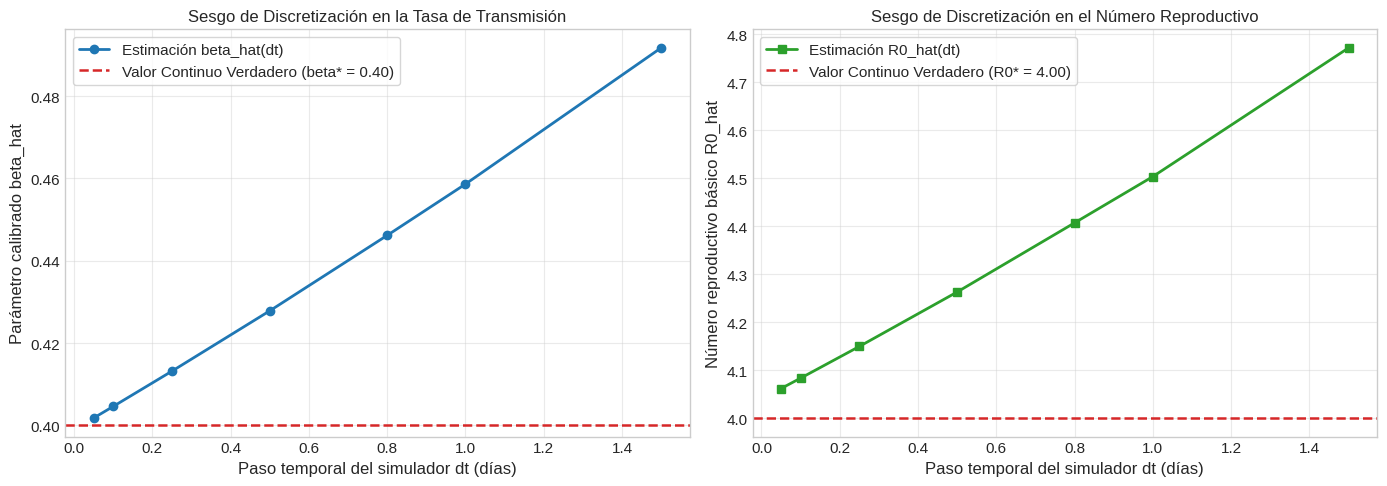

In [11]:
dt_valores = [0.05, 0.10, 0.25, 0.50, 0.80, 1.00, 1.50]
res_sesgo = experimento_sesgo_discretizacion(dt_valores, t_obs, I_obs)

beta_true = 0.40
gamma_true = 0.10
R0_true = 4.00

print("=" * 85)
print("SESGO DE DISCRETIZACIÓN EN LA CALIBRACIÓN INVERSA")
print(f"Parámetros verdaderos de referencia: beta* = {beta_true:.2f}, gamma* = {gamma_true:.2f}, R0* = {R0_true:.2f}")
print("=" * 85)
print(f"{'dt':>6s} | {'beta_hat':>10s} | {'gamma_hat':>10s} | {'R0_hat':>8s} | {'Error R0 (%)':>14s} | {'Pérdida':>10s}")
print("-" * 85)

for i in range(len(dt_valores)):
    dt_val = res_sesgo["dt"][i]
    b_h = res_sesgo["beta_hat"][i]
    g_h = res_sesgo["gamma_hat"][i]
    r0_h = res_sesgo["R0_hat"][i]
    err_r0 = ((r0_h - R0_true) / R0_true) * 100.0
    l_val = res_sesgo["loss"][i]
    print(f"{dt_val:6.2f} | {b_h:10.4f} | {g_h:10.4f} | {r0_h:8.4f} | {err_r0:+13.2f}% | {l_val:10.5f}")
print("=" * 85)

# Gráficas de análisis de sesgo
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Panel 1: beta_hat vs dt
axes[0].plot(res_sesgo["dt"], res_sesgo["beta_hat"], 'o-', color="#1f77b4", linewidth=2.0, markersize=6, label="Estimación beta_hat(dt)")
axes[0].axhline(beta_true, color="#d62728", linestyle="--", linewidth=1.8, label=f"Valor Continuo Verdadero (beta* = {beta_true:.2f})")
axes[0].set_title("Sesgo de Discretización en la Tasa de Transmisión")
axes[0].set_xlabel("Paso temporal del simulador dt (días)")
axes[0].set_ylabel("Parámetro calibrado beta_hat")
axes[0].legend(frameon=True)

# Panel 2: R0_hat vs dt
axes[1].plot(res_sesgo["dt"], res_sesgo["R0_hat"], 's-', color="#2ca02c", linewidth=2.0, markersize=6, label="Estimación R0_hat(dt)")
axes[1].axhline(R0_true, color="#d62728", linestyle="--", linewidth=1.8, label=f"Valor Continuo Verdadero (R0* = {R0_true:.2f})")
axes[1].set_title("Sesgo de Discretización en el Número Reproductivo")
axes[1].set_xlabel("Paso temporal del simulador dt (días)")
axes[1].set_ylabel("Número reproductivo básico R0_hat")
axes[1].legend(frameon=True)

plt.tight_layout()
plt.show()


## 7. Reflexiones para la Salud Pública y Toma de Decisiones

Los resultados computacionales obtenidos revelan una tendencia inequívoca:
- A medida que el paso temporal $\Delta t$ aumenta de $0.05$ a $1.50$ días, el optimizador eleva sistemáticamente $\hat{\beta}$ de $0.4018$ a $0.4918$, inflando $\hat{R}_0$ de $4.06$ a $4.77$ (un error relativo del $+19.3\%$ atribuible únicamente a la malla numérica).

### Impacto Sanitario: Cálculo del Umbral de Inmunidad Colectiva

En epidemiología teórica, la proporción crítica de la población que debe ser inmunizada mediante vacunación para extinguir la transmisión comunitaria (inmunidad de rebaño) se calcula como:

$$p_c = 1 - \frac{1}{R_0}$$

Comparando las implicaciones de política pública:
- Con el parámetro verdadero continuo ($R_0^* = 4.00$):
  $$p_c = 1 - \frac{1}{4.00} = 0.750 \implies 75.0\%$$
- Con el parámetro sesgado por discretización gruesa a $\Delta t = 1.50$ ($\hat{R}_0 = 4.77$):
  $$p_c = 1 - \frac{1}{4.77} = 0.790 \implies 79.0\%$$

Una discrepancia de $4.0\%$ en una población nacional de 5 millones de habitantes representa **200,000 personas adicionales que el Ministerio de Salud planificaría vacunar innecesariamente**, o por el contrario, la imposición de cuarentenas más prolongadas basadas en una velocidad de contagio artificialmente sobreestimada.

### Conclusión Metodológica

El error numérico de discretización no es simplemente un detalle de implementación computacional; es un factor que distorsiona las inferencias científicas y tiene consecuencias directas y tangibles en las políticas de salud pública. Para obtener estimadores no sesgados, es indispensable utilizar pasos temporales suficientemente finos o integradores adaptativos de orden superior durante la calibración inversa.
